In [1]:
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms
import torch
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [2]:
# The CIFAR-10 dataset consists of 60000 32x32 colour images in 10 classes,
# with 6000 images per class. There are 50000 training images and 10000 test images.
to_tensor_transform = transforms.Compose([
    transforms.ToTensor(),
])
cifar10_dsets = datasets.CIFAR10(root="/content/work/cifar10", download=True, transform=to_tensor_transform)
cifar10_train_dsets, cifar10_val_dsets = torch.utils.data.random_split(cifar10_dsets, [0.7, 0.3], generator=torch.Generator().manual_seed(42))
cifar10_test_dsets = datasets.CIFAR10(root="/content/work/cifar10", train=False, download=True, transform=to_tensor_transform)
len(cifar10_train_dsets), len(cifar10_val_dsets), len(cifar10_test_dsets)

(35000, 15000, 10000)

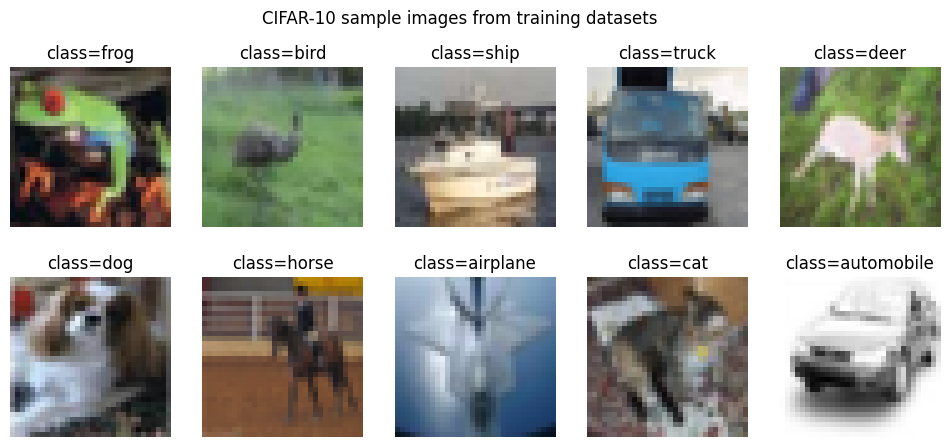

In [3]:
classes_plotted = set()
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(12, 5))
fig.suptitle('CIFAR-10 sample images from training datasets')
for dset, label in cifar10_train_dsets:
  if label not in classes_plotted:
    ax = axes.flat[len(classes_plotted)]
    ax.set_axis_off()
    ax.set_title(f'class={cifar10_dsets.classes[label]}')
    ax.imshow(np.asarray(dset.permute(1, 2, 0)))
    classes_plotted.add(label)
  if len(classes_plotted) == 10:
    break

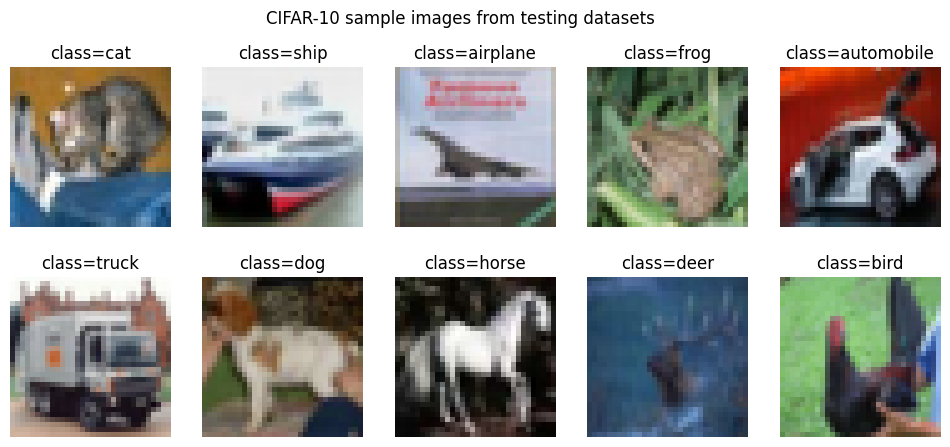

In [4]:
classes_plotted = set()
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(12, 5))
fig.suptitle('CIFAR-10 sample images from testing datasets')
for dset, label in cifar10_test_dsets:
  if label not in classes_plotted:
    ax = axes.flat[len(classes_plotted)]
    ax.set_axis_off()
    ax.set_title(f'class={cifar10_test_dsets.classes[label]}')
    ax.imshow(np.asarray(dset.permute(1,2,0)))
    classes_plotted.add(label)
  if len(classes_plotted) == 10:
    break

In [5]:
def create_with_hparams(lr, hidden_size, batch_size):
  fcnn_model = torch.nn.Sequential(
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)), # go from [0,255] to [-1,1]
    torch.nn.Flatten(),
    torch.nn.Linear(in_features=32*32*3, out_features=hidden_size),
    torch.nn.ReLU(),
    torch.nn.Linear(in_features=hidden_size, out_features=10),
  )
  for layer in fcnn_model:
    if isinstance(layer, torch.nn.Linear):
      # Apply Xavier Uniform to weights
      torch.nn.init.xavier_uniform_(layer.weight)
      # Initialize biases to zero
      if layer.bias is not None:
          torch.nn.init.constant_(layer.bias, 0.0)
  fcnn_model.to(device)
  optimizer = torch.optim.Adam(params=fcnn_model.parameters(), lr=lr)
  loader_opts = {'batch_size': batch_size, 'shuffle': True, 'num_workers': 8, 'pin_memory': True}
  train_data_loader = torch.utils.data.DataLoader(
      dataset=cifar10_train_dsets,
      **loader_opts)
  val_data_loader = torch.utils.data.DataLoader(
      dataset=cifar10_val_dsets,
      **loader_opts)

  return fcnn_model, optimizer, train_data_loader, val_data_loader

In [17]:
def train_once(epoch, model, data_loader, optimizer, loss_fn):
  model.train()
  avg_loss = 0.0
  avg_acc = 0.0
  for X, y in data_loader:
    X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    logits = model(X)
    loss = loss_fn(logits, y)
    loss.backward()
    optimizer.step()
    avg_loss += loss.item()
    avg_acc += (logits.argmax(dim=1) == y).float().mean().item()
  avg_loss /= len(data_loader)
  avg_acc /= len(data_loader)
  return avg_loss, avg_acc


def eval_once(epoch, model, data_loader, loss_fn):
  model.eval()
  avg_loss = 0.0
  avg_acc = 0.0
  for X, y in data_loader:
    X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)
    with torch.no_grad():
      logits = model(X)
      loss = loss_fn(logits, y)
      avg_loss += loss.item()
      avg_acc += (logits.argmax(dim=1) == y).float().mean().item()
  avg_loss /= len(data_loader)
  avg_acc /= len(data_loader)
  return avg_loss, avg_acc


def train_with_hparams(lr, hidden_size, batch_size, n_epochs=None):
  fcnn_model, optimizer, train_data_loader, val_data_loader = create_with_hparams(lr, hidden_size, batch_size)
  loss_fn = torch.nn.CrossEntropyLoss()
  train_losses = []
  val_losses = []
  train_accuracies = []
  val_accuracies = []
  n_epochs = 20 if n_epochs is None else n_epochs
  for epoch in range(n_epochs):
    avg_train_loss, avg_train_acc = train_once(epoch, fcnn_model, train_data_loader, optimizer, loss_fn)
    avg_val_loss, avg_val_acc = eval_once(epoch, fcnn_model, val_data_loader, loss_fn)
    print(f'[epoch {epoch}/{n_epochs}], train_loss={avg_train_loss:.4f} val_loss={avg_val_loss:.4f}')
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accuracies.append(avg_train_acc)
    val_accuracies.append(avg_val_acc)
  return fcnn_model, train_losses, val_losses, train_accuracies, val_accuracies

In [7]:
hyperparam_grid = {
    'lr': [1e-2, 1e-3, 1e-4],
    'hidden_size': [128, 256, 512],
    'batch_size': [64, 128],
}
grid_search_results = []
for lr in hyperparam_grid['lr']:
  for hidden_size in hyperparam_grid['hidden_size']:
    for batch_size in hyperparam_grid['batch_size']:
      print(f'lr={lr}, hidden_size={hidden_size}, batch_size={batch_size}')
      model, train_losses, val_losses = train_with_hparams(lr, hidden_size, batch_size)
      grid_search_results.append(
          {
              'lr': lr,
              'hidden_size': hidden_size,
              'batch_size': batch_size,
              'train_losses': train_losses,
              'val_losses': val_losses,
          }
      )
print(grid_search_results)
test_data_loader = torch.utils.data.DataLoader(dataset=cifar10_test_dsets, batch_size=100, shuffle=True, num_workers=8, pin_memory=True,)


lr=0.01, hidden_size=128, batch_size=64
[epoch 0/20], train_loss=2.5139 val_loss=1.9754
[epoch 1/20], train_loss=2.2248 val_loss=2.2852
[epoch 2/20], train_loss=2.3334 val_loss=2.3450
[epoch 3/20], train_loss=2.2148 val_loss=2.1343
[epoch 4/20], train_loss=2.2332 val_loss=2.3765
[epoch 5/20], train_loss=2.1427 val_loss=2.3119
[epoch 6/20], train_loss=2.1140 val_loss=2.2531
[epoch 7/20], train_loss=2.1594 val_loss=2.3706
[epoch 8/20], train_loss=2.0959 val_loss=2.1227
[epoch 9/20], train_loss=2.0240 val_loss=2.2181
[epoch 10/20], train_loss=2.0545 val_loss=2.4322
[epoch 11/20], train_loss=1.9673 val_loss=2.1635
[epoch 12/20], train_loss=1.9637 val_loss=2.2780
[epoch 13/20], train_loss=1.9964 val_loss=2.1648
[epoch 14/20], train_loss=1.9082 val_loss=2.1097
[epoch 15/20], train_loss=1.9138 val_loss=2.0694
[epoch 16/20], train_loss=1.9286 val_loss=2.0936
[epoch 17/20], train_loss=1.8692 val_loss=2.2070
[epoch 18/20], train_loss=1.8713 val_loss=2.2534
[epoch 19/20], train_loss=1.8659 val_lo

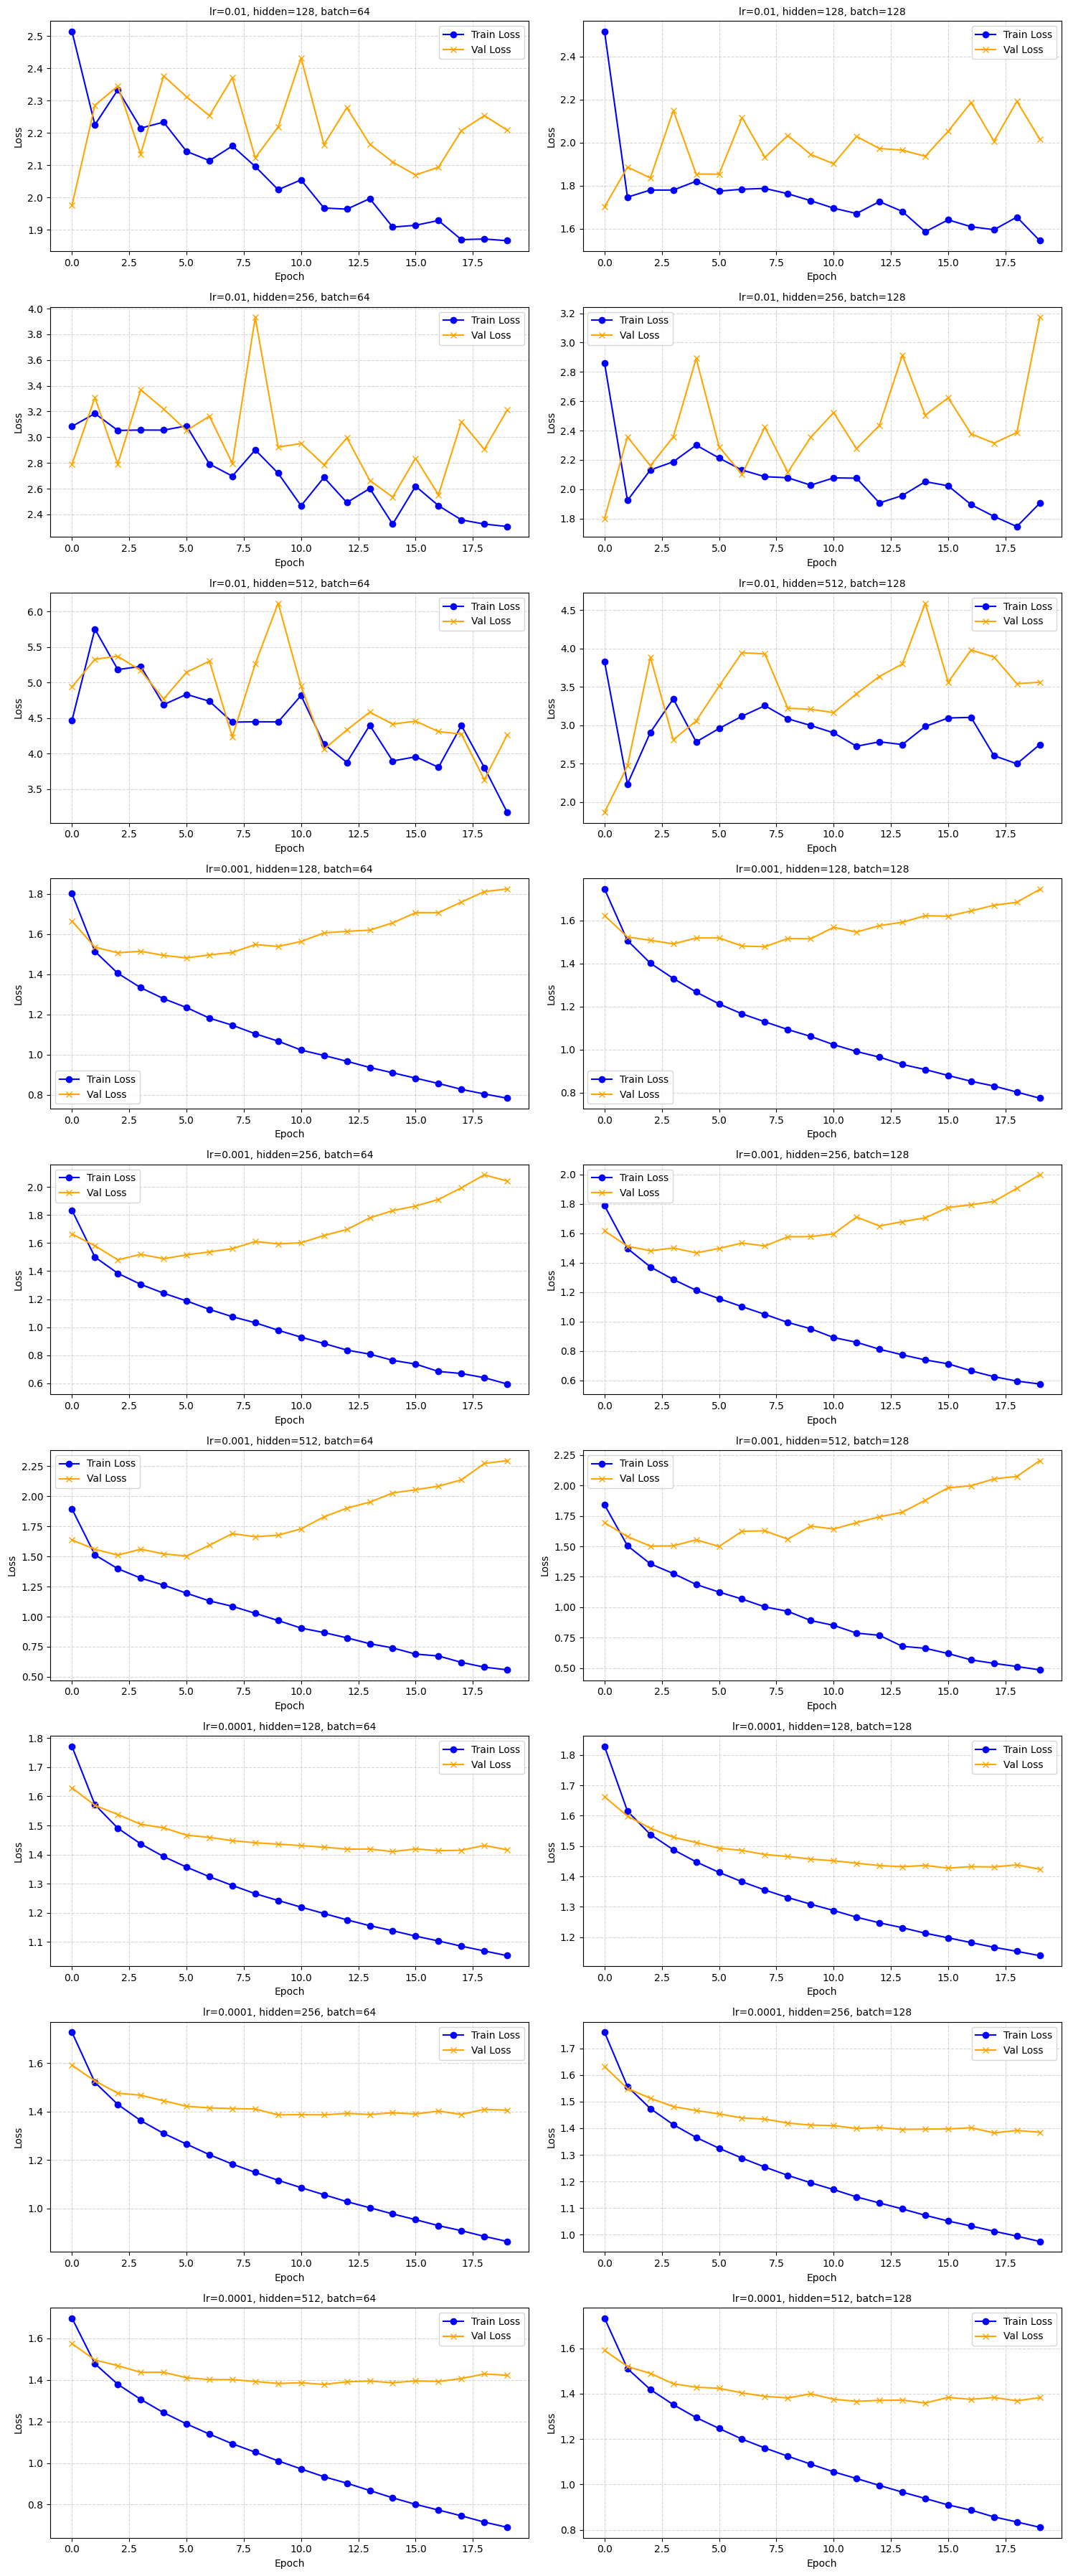

In [8]:
import matplotlib.pyplot as plt

# Calculate grid size based on number of completed experiments
num_experiments = len(grid_search_results)
n_cols = 2
n_rows = (num_experiments + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for idx, result in enumerate(grid_search_results):
    ax = axes[idx]
    epochs = range(len(result['train_losses']))

    ax.plot(epochs, result['train_losses'], label='Train Loss', color='blue', marker='o')
    ax.plot(epochs, result['val_losses'], label='Val Loss', color='orange', marker='x')

    title = f"lr={result['lr']}, hidden={result['hidden_size']}, batch={result['batch_size']}"
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

# Hide unused subplots
for idx in range(num_experiments, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

# Discussion of results from GridSearch

The loss curves for lr=0.01 exhibit random fluctuations and training is unstable.

The loss curves for lr=0.001 show that validation loss quickly diverges from the training loss and grows, the network is overfitting the training data. A larger hidden layer size overfits faster, likely due to a more complex network.

The lr=0.0001, hidden=512, batch=128 has the best validation loss at the final epoch and it goes below 1.4 the quickest, near epoch 8, reaches the lowest validation loss around epoch=14

In [27]:
# Retrain with best hyperparams up to best epoch from the plot
best_hparams = {'lr':0.0001, 'hidden_size':512, 'batch_size':128}
model, train_losses, val_losses, train_accs, val_accs = train_with_hparams(n_epochs=15, **best_hparams)

[epoch 0/15], train_loss=1.7332 val_loss=1.5950
[epoch 1/15], train_loss=1.5123 val_loss=1.5160
[epoch 2/15], train_loss=1.4206 val_loss=1.4770
[epoch 3/15], train_loss=1.3508 val_loss=1.4531
[epoch 4/15], train_loss=1.2952 val_loss=1.4326
[epoch 5/15], train_loss=1.2457 val_loss=1.4192
[epoch 6/15], train_loss=1.2006 val_loss=1.4065
[epoch 7/15], train_loss=1.1594 val_loss=1.3953
[epoch 8/15], train_loss=1.1238 val_loss=1.3934
[epoch 9/15], train_loss=1.0869 val_loss=1.3838
[epoch 10/15], train_loss=1.0561 val_loss=1.3864
[epoch 11/15], train_loss=1.0245 val_loss=1.3723
[epoch 12/15], train_loss=0.9923 val_loss=1.3840
[epoch 13/15], train_loss=0.9645 val_loss=1.3787
[epoch 14/15], train_loss=0.9357 val_loss=1.3855


Text(0.5, 0.98, "{'lr': 0.0001, 'hidden_size': 512, 'batch_size': 128}")

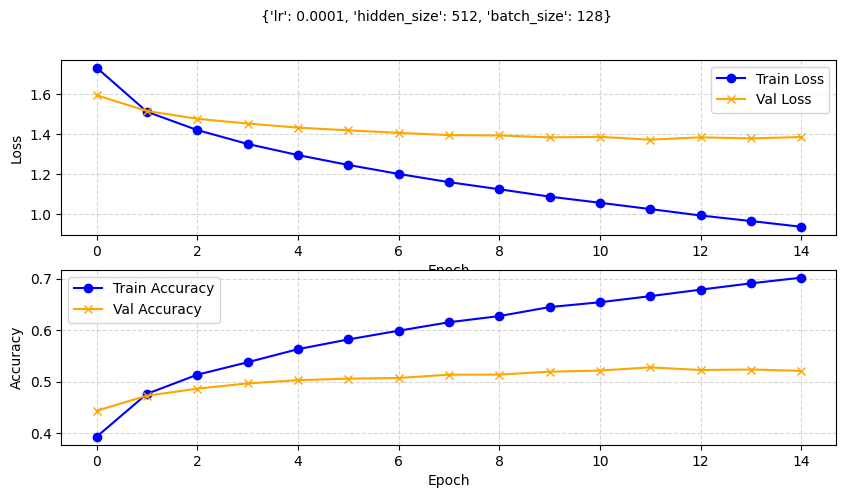

In [28]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(10, 5))
epochs = range(len(train_losses))
ax[0].plot(epochs, train_losses, label='Train Loss', color='blue', marker='o')
ax[0].plot(epochs, val_losses, label='Val Loss', color='orange', marker='x')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[1].plot(epochs, train_accs, label='Train Accuracy', color='blue', marker='o')
ax[1].plot(epochs, val_accs, label='Val Accuracy', color='orange', marker='x')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.5)

title = f"{best_hparams}"
fig.suptitle(title, fontsize=10)